# FTSE 100 Market Analysis

## 1. Introduction

The FTSE 100 is the index of the 100 largest companies listed on the London Stock Exchange. This notebook looks at how it has behaved since January 2019: how much it returned, how volatile it was, how deep its falls were and how long they took to recover. It then breaks the index into broad sectors to see which parts of the market carried the most risk and how closely they move together.

The period includes three very different shocks: the Covid crash of March 2020, the Russian invasion of Ukraine in February 2022, and the September 2022 mini budget. Comparing how the index reacted to each is one of the more interesting results.

All calculations live in small tested functions in `src/`, so this notebook mostly loads data, calls those functions and explains the results.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# Run from the project root whether the notebook is opened from notebooks/ or the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.clean import clean_returns
from src.metrics import (
    annualised_return, annualised_volatility, drawdown, log_returns,
    max_drawdown, rolling_volatility, sector_returns,
)
from src import plots

plots.use_style()
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4f}".format)

## 2. Data

Daily prices come from Yahoo Finance through the `yfinance` package, downloaded by `python -m src.fetch`. The index is `^FTSE`. The constituents are the 100 members after the 1 October 2026 index review, each assigned to one of 11 broad sectors in `data/constituents.csv`.

Constituent prices are adjusted for splits and dividends. The index is a price index, so it does **not** include dividends. This matters when comparing sector returns with the index return later on.

The analysis is fixed to end on **19 October 2026**, the last completed trading day when the data was downloaded. Fixing the end date means the numbers quoted in this notebook and the README stay the same if the data is downloaded again later.

In [2]:
ANALYSIS_END = "2026-10-19"

index_prices = pd.read_csv(ROOT / "data/raw/ftse100_index.csv", index_col=0, parse_dates=True)["^FTSE"]
stock_prices = pd.read_csv(ROOT / "data/raw/constituents_prices.csv", index_col=0, parse_dates=True)
constituents = pd.read_csv(ROOT / "data/constituents.csv")
failed = (ROOT / "data/raw/failed_tickers.txt").read_text().split()

index_prices = index_prices.loc[:ANALYSIS_END]
stock_prices = stock_prices.loc[:ANALYSIS_END]

print(f"Index: {len(index_prices)} trading days, {index_prices.index[0]:%d %b %Y} to {index_prices.index[-1]:%d %b %Y}")
print(f"Constituents with data: {stock_prices.shape[1]} of {len(constituents)}")
print(f"Dropped tickers: {', '.join(failed) if failed else 'none'}")

Index: 1969 trading days, 02 Jan 2019 to 19 Oct 2026
Constituents with data: 100 of 100
Dropped tickers: none


Not every company has prices back to 2019. Some listed or were spun off later, so they only contribute to their sector from their first trading day.

In [3]:
first_day = stock_prices.apply(pd.Series.first_valid_index)
late = first_day[first_day > "2019-01-31"].sort_values()
constituents.set_index("ticker").loc[late.index, ["company", "sector"]].assign(first_price=late.dt.date)

,company,sector,first_price
CCEP.L,Coca-Cola Europacific Partners,Consumer Staples,2019-03-28
AAF.L,Airtel Africa,Communication Services,2019-06-28
MNG.L,M&G,Financials,2019-10-21
HLN.L,Haleon,Health Care,2022-07-18
ITH.L,Ithaca Energy,Energy,2022-11-09
MTLN.L,Metlen Energy & Metals,Utilities,2025-08-04


### Cleaning

Two problems in the Yahoo data are fixed by `clean_returns` (see `src/clean.py` for the reasoning):

* **Endeavour Mining** traded very thinly in London before its main listing moved there in June 2021. Its price is unchanged on most days before then, which creates false jumps of +34% and −55%. Those returns are removed.
* **IAG** shows a 37% fall on 14 September 2020 around its rights issue, which Yahoo has not adjusted for. That single day is removed.

Removed values become missing, so the stock simply drops out of its sector average on those days. Nothing is filled in with a guess.

In [4]:
# Daily log returns: ln(P_t / P_{t-1}). They add up over time, which suits volatility work.
index_returns = log_returns(index_prices)
stock_returns, cleaning_report = clean_returns(log_returns(stock_prices))
cleaning_report

,ticker,rule,values_removed
0,EDV.L,stale prices up to 2021-06-14,618
1,IAG.L,unadjusted rights issue on 2020-09-14,1


## 3. Index overview

The top chart shows the index level and the bottom one shows each day's log return. Large returns in either direction cluster together, most obviously in March 2020. This clustering is why volatility is worth measuring over a rolling window rather than as one number for the whole period.

Index level: 6,734 to 10,765 (59.9%, excluding dividends)
Annualised return: 6.2%
Annualised volatility: 15.7%
Worst days:
Date
2020-03-12    -11.5%
2020-03-09     -8.0%
2020-03-27     -5.4%


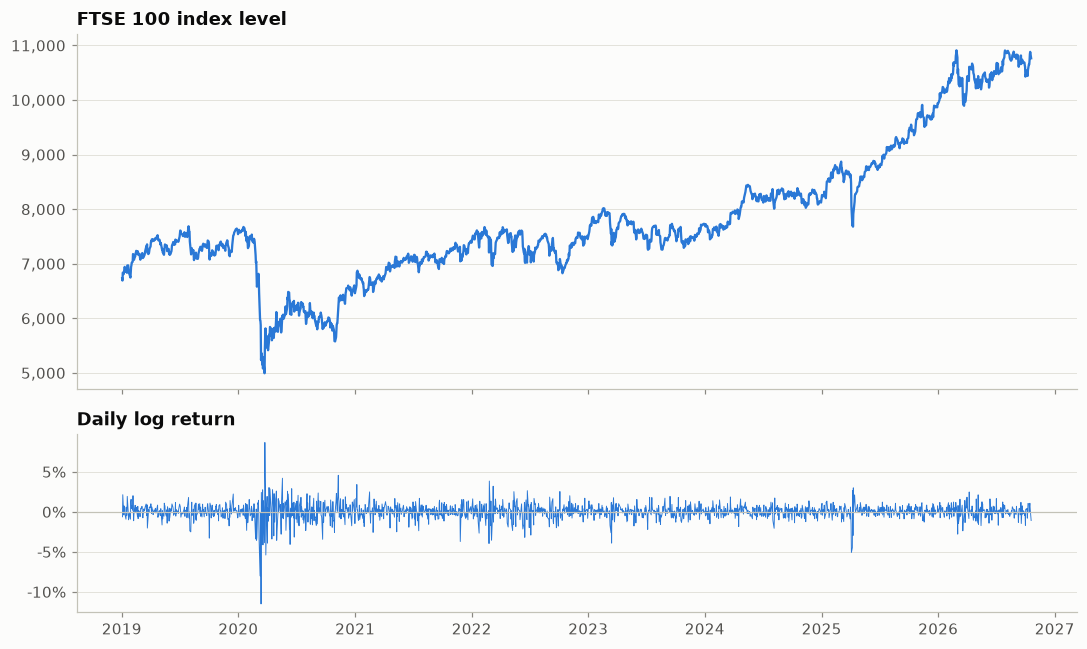

In [5]:
fig = plots.plot_index(index_prices, index_returns)
fig.savefig(FIGURES / "index_overview.png", bbox_inches="tight")

growth = index_prices.iloc[-1] / index_prices.iloc[0] - 1
print(f"Index level: {index_prices.iloc[0]:,.0f} to {index_prices.iloc[-1]:,.0f} ({growth:.1%}, excluding dividends)")
print(f"Annualised return: {annualised_return(index_returns):.1%}")
print(f"Annualised volatility: {annualised_volatility(index_returns):.1%}")
print("Worst days:"); print(index_returns.nsmallest(3).map("{:.1%}".format).to_string())

## 4. Volatility

Volatility here is the standard deviation of daily returns over the previous 30 trading days, multiplied by √252 to put it on a yearly scale. Annualising lets the figure be compared with the usual way volatility is quoted, for example "the FTSE 100 has an annual volatility of about 16%".

The dashed line is the median over the whole period, as a sense of a normal level. The labels mark the highest reading around each event. Because the window looks back 30 days, the peak arrives a few weeks after the shock itself.

,peak_date,peak_volatility,times_median
Covid crash,2020-04-17,0.6342,5.6396
Ukraine invasion,2022-03-18,0.2615,2.3258
Mini budget,2022-10-11,0.1722,1.5312
US tariffs,2025-04-23,0.2739,2.4359


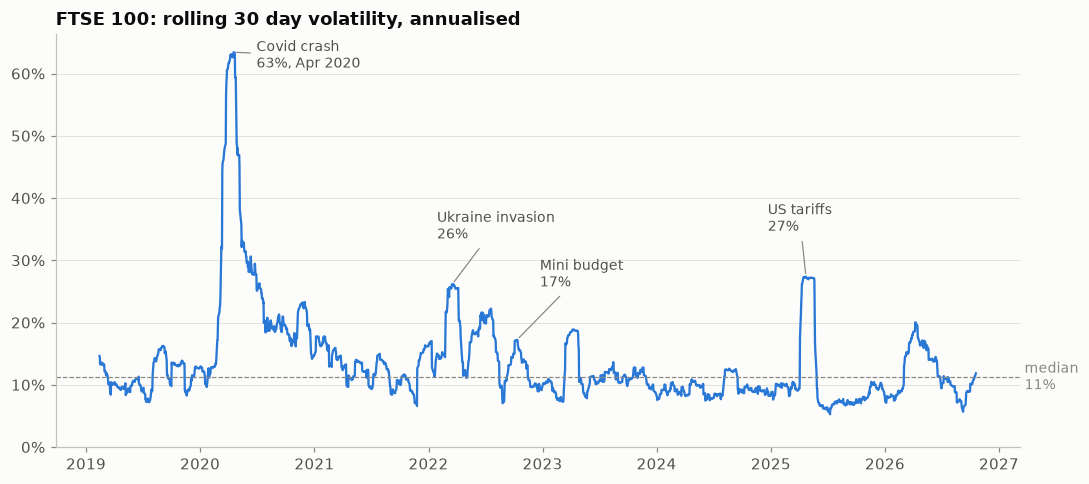

In [6]:
vol = rolling_volatility(index_returns, window=30)

def peak(start, end):
    """Date of the highest volatility reading between two dates."""
    return vol.loc[start:end].idxmax()

covid, ukraine = peak("2020-02", "2020-06"), peak("2022-02", "2022-04")
minibudget, tariffs = peak("2022-09-23", "2022-11"), peak("2025-04", "2025-05")

events = [
    (covid, f"Covid crash\n{vol[covid]:.0%}, {covid:%b %Y}", (15, -10)),
    (ukraine, f"Ukraine invasion\n{vol[ukraine]:.0%}", (-10, 30)),
    (minibudget, f"Mini budget\n{vol[minibudget]:.0%}", (15, 35)),
    (tariffs, f"US tariffs\n{vol[tariffs]:.0%}", (-25, 30)),
]
fig = plots.plot_volatility(vol, events, median=vol.median())
fig.savefig(FIGURES / "volatility.png", bbox_inches="tight")

pd.DataFrame(
    {"peak_date": [covid, ukraine, minibudget, tariffs],
     "peak_volatility": [vol[covid], vol[ukraine], vol[minibudget], vol[tariffs]]},
    index=["Covid crash", "Ukraine invasion", "Mini budget", "US tariffs"],
).assign(peak_date=lambda d: d.peak_date.dt.date, times_median=lambda d: d.peak_volatility / vol.median())

The Covid crash dwarfs everything else: volatility reached about six times its normal level. The more surprising result is the **mini budget**. Despite the turmoil in gilts and sterling in late September 2022, FTSE 100 volatility only rose to about 17%, well below the readings after the Ukraine invasion or the April 2025 tariff announcements, and the index fell only about 5% between 22 September and 12 October.

A likely reason is that FTSE 100 companies earn most of their revenue abroad, so a weaker pound raises the sterling value of their earnings. The mini budget was mainly a crisis for UK government borrowing and the currency, not for these large international companies.

In [7]:
fall = index_prices.loc["2022-10-12"] / index_prices.loc["2022-09-22"] - 1
print(f"Index move 22 Sep to 12 Oct 2022: {fall:.1%}")

Index move 22 Sep to 12 Oct 2022: -4.7%


## 5. Drawdowns

A drawdown is how far the index sits below its highest level so far. It answers the question an investor actually feels: "how much am I down from the top?" The maximum drawdown is the worst such fall, and the recovery date is the first day the index closed back at its previous peak.

Worst drawdown: -35.0%
Peak 29 Jul 2019, trough 23 Mar 2020, recovered 06 Jan 2023
Peak to trough: 166 trading days
Trough to recovery: 702 trading days (2.8 years)
Worst drawdown since 2023: -13.4% on 09 Apr 2025


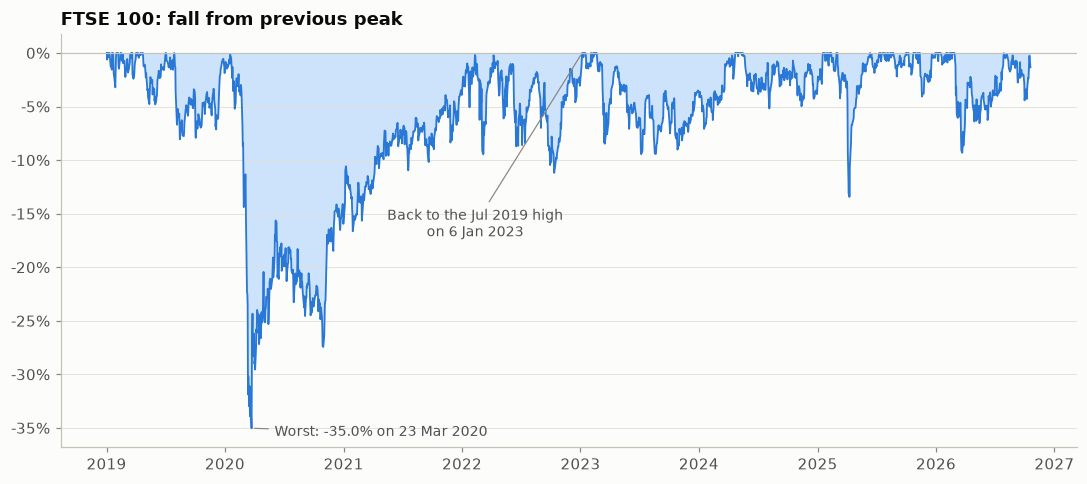

In [8]:
dd = drawdown(index_prices)
worst = max_drawdown(index_prices)
fig = plots.plot_drawdown(dd, worst)
fig.savefig(FIGURES / "drawdown.png", bbox_inches="tight")

days = lambda a, b: len(index_prices.loc[a:b]) - 1  # trading days between two dates
print(f"Worst drawdown: {worst['depth']:.1%}")
print(f"Peak {worst['peak_date']:%d %b %Y}, trough {worst['trough_date']:%d %b %Y}, recovered {worst['recovery_date']:%d %b %Y}")
print(f"Peak to trough: {days(worst['peak_date'], worst['trough_date'])} trading days")
print(f"Trough to recovery: {days(worst['trough_date'], worst['recovery_date'])} trading days "
      f"({(worst['recovery_date'] - worst['trough_date']).days / 365.25:.1f} years)")
print(f"Worst drawdown since 2023: {dd.loc['2023':].min():.1%} on {dd.loc['2023':].idxmin():%d %b %Y}")

The index fell 35% from its July 2019 high to the bottom on 23 March 2020, and took almost three years to get back. Falls are fast and recoveries are slow: the decline took about 8 months, most of it in a few weeks of March, while the recovery took 702 trading days. Since 2023 the worst fall has been about 13%, during the April 2025 tariff shock.

These figures exclude dividends. With dividends reinvested, the recovery would have come sooner.

## 6. Sectors

Each sector's daily return is the **equal weighted** average of its stocks' returns: every company counts the same, however large it is. This is simpler than market cap weighting and stops a giant like Shell or AstraZeneca from dominating its sector, but it means these figures will differ from official FTSE sector indices. Unlike the index, the sector returns include dividends.

Return and volatility are annualised in the same way as for the index. The last column divides return by volatility, a rough measure of how much return each unit of risk earned.

In [9]:
sector_daily = sector_returns(stock_returns, constituents)

sector_table = pd.DataFrame({
    "stocks": constituents["sector"].value_counts(),
    "ann_return": annualised_return(sector_daily),
    "ann_vol": annualised_volatility(sector_daily),
})
sector_table["return_per_risk"] = sector_table["ann_return"] / sector_table["ann_vol"]
sector_table = sector_table.sort_values("ann_vol")
sector_table.style.format({"ann_return": "{:.1%}", "ann_vol": "{:.1%}", "return_per_risk": "{:.2f}"})

,stocks,ann_return,ann_vol,return_per_risk
sector,,,,
Consumer Staples,11,6.4%,15.7%,0.41
Health Care,5,6.3%,17.7%,0.36
Industrials,18,13.0%,19.1%,0.68
Communication Services,8,6.6%,19.6%,0.33
Utilities,6,8.4%,20.3%,0.41
Financials,25,13.1%,20.9%,0.63
Real Estate,5,1.2%,24.3%,0.05
Technology,2,17.5%,24.6%,0.71
Consumer Discretionary,10,8.3%,26.4%,0.32


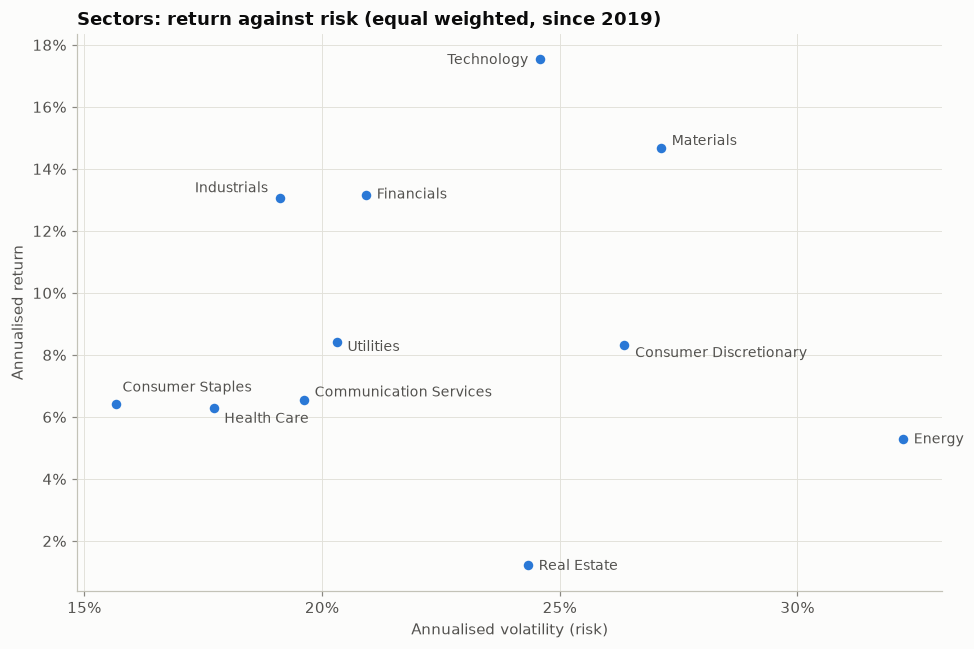

In [10]:
offsets = {"Consumer Staples": (4, 8), "Health Care": (7, -10), "Industrials": (-8, 4), "Communication Services": (7, 2),
           "Utilities": (7, -6), "Financials": (7, -2), "Technology": (-8, -3),
           "Consumer Discretionary": (7, -8), "Materials": (7, 2)}
fig = plots.plot_sector_risk_return(sector_table, offsets)
fig.savefig(FIGURES / "sector_risk_return.png", bbox_inches="tight")

**Consumer Staples** (food, drink, tobacco, household goods and supermarkets) is the steadiest sector, with volatility of about 16%, close to the index. **Energy** is the riskiest at about 32%, twice as volatile, because oil and gas prices swung wildly over the period.

Higher risk did not reliably bring higher return. Energy and Real Estate were both volatile but returned little, while Industrials and Financials earned about 13% a year with only middling risk. Technology has the best return, but it contains only two companies, so that figure says more about those two businesses than about a sector.

The Covid crash shows the same split between defensive and cyclical sectors very clearly:

In [11]:
# Total fall from the index's pre crash close (19 Feb 2020) to the bottom (23 Mar 2020)
crash = np.expm1(sector_daily.loc["2020-02-20":"2020-03-23"].sum()).sort_values()
index_crash = index_prices.loc["2020-03-23"] / index_prices.loc["2020-02-19"] - 1
print(f"FTSE 100 index: {index_crash:.1%}")
crash.map("{:.1%}".format).to_frame("fall_19_feb_to_23_mar_2020")

FTSE 100 index: -33.0%


,fall_19_feb_to_23_mar_2020
sector,
Consumer Discretionary,-51.9%
Energy,-43.0%
Financials,-40.3%
Technology,-37.5%
Industrials,-37.4%
Communication Services,-35.8%
Real Estate,-35.6%
Utilities,-32.3%
Materials,-31.5%


Consumer Discretionary, which includes airlines, hotels and retailers, lost about half its value in five weeks. Health Care lost about a fifth.

## 7. Correlation

Correlation measures how closely two sectors' daily returns move together, from 0 (unrelated) to 1 (moving in lockstep). Low correlation is what makes diversification work: combining sectors that do not move together reduces the risk of the whole portfolio.

Average correlation between sectors: 0.48
Most correlated:  Financials and Industrials (0.85)
Least correlated: Energy and Technology (0.18)
Average correlation with the other sectors:
sector
Energy                    0.34
Technology                0.37
Materials                 0.40
Health Care               0.40
Utilities                 0.42
Real Estate               0.48
Consumer Staples          0.51
Consumer Discretionary    0.56
Communication Services    0.57
Industrials               0.61
Financials                0.62


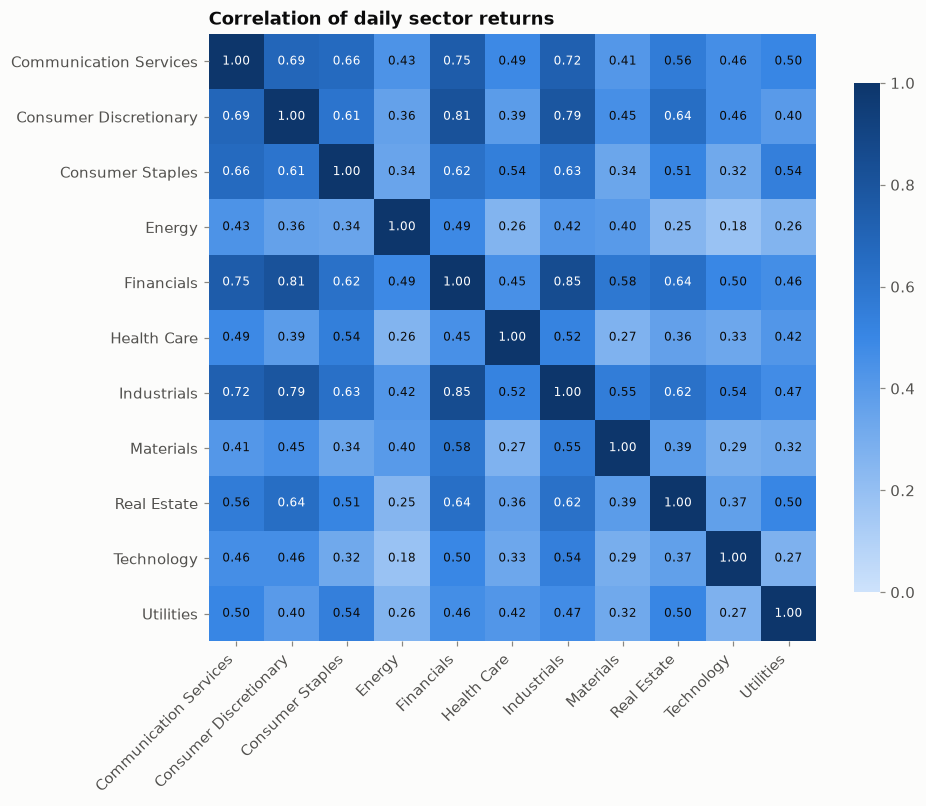

In [12]:
corr = sector_daily.corr()
fig = plots.plot_correlation(corr)
fig.savefig(FIGURES / "sector_correlation.png", bbox_inches="tight")

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"Average correlation between sectors: {pairs.mean():.2f}")
print(f"Most correlated:  {' and '.join(pairs.idxmax())} ({pairs.max():.2f})")
print(f"Least correlated: {' and '.join(pairs.idxmin())} ({pairs.min():.2f})")
print("Average correlation with the other sectors:")
print(((corr.sum() - 1) / (len(corr) - 1)).sort_values().map("{:.2f}".format).to_string())

Every pair of sectors is positively correlated: on a typical day most of the market moves in the same direction. Financials and Industrials are the most tightly linked (0.85), since both depend on the health of the economy. Energy is the least connected to the rest, because its returns are driven mainly by oil and gas prices rather than the UK economy. That makes it the best diversifier here, even though it is also the most volatile sector.

## 8. Findings

1. **Covid was the defining shock.** The FTSE 100 fell 35% from its July 2019 high to 23 March 2020, and did not get back to that level until 6 January 2023, almost three years later. Its 30 day volatility peaked at 63%, about six times its normal level.
2. **The mini budget barely moved the FTSE 100.** Volatility peaked at about 17% in October 2022, lower than after the Ukraine invasion (26%) or the April 2025 tariff shock (27%). The index's mostly overseas earnings likely protected it from a crisis centred on gilts and sterling.
3. **Sector risk differs by a factor of two, and more risk did not mean more return.** Consumer Staples was the steadiest sector (16% volatility) and Energy the riskiest (32%). Energy and Real Estate returned little for their risk, while Industrials and Financials earned about 13% a year with middling volatility.
4. **Defensive sectors held up in the crash, and Energy is the best diversifier.** Between 19 February and 23 March 2020, Health Care fell 21% while Consumer Discretionary fell 52%. Energy has the lowest average correlation with the other sectors (0.34).

## 9. Limitations

* **Unofficial data.** yfinance scrapes Yahoo Finance and is not an official data feed. Two known errors were cleaned, but others may remain. Other large one day moves were checked by eye, not against a second source.
* **Survivorship bias.** Today's constituent list is used for every year since 2019. Companies that left the index are missing, and companies that joined after strong growth are included, which flatters past sector returns.
* **Equal weighted sectors.** Every stock counts the same within its sector, so these figures differ from market cap weighted FTSE sector indices.
* **Index excludes dividends, stocks include them.** Index figures are price returns and sector figures are total returns, so the two are not directly comparable.
* **Shorter histories and small sectors.** Six companies have shorter price histories and Endeavour's data starts in June 2021 after cleaning. Energy has 3 stocks and Technology 2, so their figures depend heavily on individual companies.
* **IAG's price level still contains the rights issue fall.** Only that day's return is removed, so its return and volatility are correct but its raw price is not.
* **Dropped tickers:** none. All 100 tickers downloaded successfully.